# 08 · How deep does the WCC reach in 1, 5 and 30 minutes, and can it follow a kilonova's colour evolution?

A kilonova fades by ~1 mag/day in the blue while the red side lingers, so the science is in the *colour* evolution over the first week: that is what separates lanthanide-poor (blue) from lanthanide-rich (red) ejecta. The question for the Lazuli Wide-field Context Camera (WCC) is how deep each filter goes in a short visit, and whether a GW170817-like event at 40 or 200 Mpc stays above the limit in g *and* z long enough to measure g − z.

**Instrument / code:** Lazuli WCC (Sony IMX455 "zwo" detector, u g r i z bb filters), `wcc-etc` 0.1.0: `get_scene`, `Simulation.from_sensorfilter`, `get_image_snr(time, mags=...)`, `get_image_exptime_for_snr`.

## Prompt to try in Jupyter AI

> Using the `wcc_etc` package (Lazuli WCC exposure time calculator), compute the 5σ point-source limiting magnitude in each WCC filter on the Sony IMX455 (`zwo:u`, `zwo:g`, `zwo:r`, `zwo:i`, `zwo:z`, `zwo:bb`) for exposure times from 10 s to 1 h.
> Use a flat-in-f_ν source (`get_scene("flat", mag=..., magsys="abmag")`) on the default zodiacal background so the limits are AB magnitudes, build each with `Simulation.from_sensorfilter`, and sweep magnitude with `sim.get_image_snr(t, mags=...)`, interpolating to SNR = 5.
> Plot limiting magnitude vs exposure time (log x-axis), one line per filter, and print a table of the limits at 1, 5 and 30 min.
> Then overlay a GW170817/AT2017gfo-like kilonova at 40 and 200 Mpc at ~1 and ~5 days (state the absolute AB magnitudes you assume), and print the exposure time needed for SNR = 10 in g and z at day 5 and 200 Mpc.
> State the noise model assumptions (aperture, background, read noise) and check that the limits scale as expected (≈ +1.25 log t when background-limited).

## Setup

A flat-$f_\nu$ spectrum normalised in AB has the same AB magnitude in every band, so a single scene gives AB limiting magnitudes for all six filters. The background is the default zodiacal light ($V = 22.5$ mag arcsec$^{-2}$). `from_sensorfilter` picks each filter's throughput curve and PSF (all six are in focus, so an Airy PSF with the default 70 mas aperture).

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import os, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
# plt.style.use('gks')
import wcc_etc
from wcc_etc import get_scene, Simulation

print('wcc_etc', wcc_etc.__version__)
THUMB = Path('thumbs/08_fast_transient_depth.png')
FILTERS = ['u', 'g', 'r', 'i', 'z', 'bb']
COLORS = {'u': '#30638e', 'g': '#00798c', 'r': '#66a182', 'i': '#edae49', 'z': '#d1495b', 'bb': '0.25'}

sims = {}
for f in FILTERS:
    scene = get_scene('flat', mag=24, magsys='abmag', bandpass='johnson_v')
    sims[f] = Simulation.from_sensorfilter(f'zwo:{f}', scene)
s = sims['r']
print(f"read noise {s.sensor.read_noise:.2f}, dark {s.sensor.dark_current:.4f}, full well {s.sensor.saturation_e:.0f}")
print('PSF per filter:', {f: type(sims[f].default_psf).__name__ for f in FILTERS})

wcc_etc 0.1.0


read noise 3.04 electron / pix, dark 0.0031 electron / (pix s), full well 16275 electron
PSF per filter: {'u': 'AiryPSF', 'g': 'AiryPSF', 'r': 'AiryPSF', 'i': 'AiryPSF', 'z': 'AiryPSF', 'bb': 'AiryPSF'}


## Limiting magnitude vs exposure time

For each exposure time, sweep the source magnitude (`mags=`) and interpolate to SNR = 5. One read per exposure (`n_reads=1`).

In [2]:
MAGS = np.arange(18, 31.01, 0.1)
TIMES = np.logspace(1, np.log10(3600), 25)          # 10 s .. 1 h

def limit(sim, t, snr=5.0):
    s = np.asarray(sim.get_image_snr(t, mags=MAGS, warn=False)['snr'])
    return float(np.interp(snr, s[::-1], MAGS[::-1]))  # SNR decreases with mag

t0 = time.time()
lim = {f: np.array([limit(sims[f], t) for t in TIMES]) for f in FILTERS}
print(f'grid done in {time.time()-t0:.0f} s\n')

print(f"{'filter':>6} {'1 min':>7} {'5 min':>7} {'30 min':>7}   (5-sigma AB)")
table = {}
for f in FILTERS:
    table[f] = [limit(sims[f], t) for t in (60, 300, 1800)]
    print(f"{f:>6} " + ' '.join(f'{m:7.2f}' for m in table[f]))

# sanity check: slope per decade of time between 5 and 30 min (background-limited -> 1.25 mag/dex)
for f in FILTERS:
    slope = (table[f][2] - table[f][1]) / np.log10(1800 / 300)
    print(f'{f}: d(m_lim)/d(log t) = {slope:.2f}')

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


grid done in 22 s

filter   1 min   5 min  30 min   (5-sigma AB)


     u   23.65   25.35   27.09


     g   26.14   27.71   29.13


     r   25.47   27.06   28.49


     i   24.34   25.99   27.55


     z   23.16   24.85   26.52


    bb   26.57   28.03   29.30
u: d(m_lim)/d(log t) = 2.24
g: d(m_lim)/d(log t) = 1.82
r: d(m_lim)/d(log t) = 1.84
i: d(m_lim)/d(log t) = 2.01
z: d(m_lim)/d(log t) = 2.15
bb: d(m_lim)/d(log t) = 1.64


The slopes come out at 1.6–2.2 mag per decade of time, between the sky-limited value (1.25) and the read-noise-limited value (2.5): with 17 mas pixels the zodiacal light per pixel is tiny, so read noise (which carries a ×2 margin in the config) still matters at 30 min. Co-adding many short frames therefore costs depth, which matters for the cadence design.

## A GW170817-like kilonova

**Assumption** (not computed here): rough absolute AB magnitudes of AT2017gfo read off its published light curves (e.g. Villar et al. 2017; Drout et al. 2017), good to ~±0.5 mag. Day 1 is nearly flat across *griz*; by day 5 the blue has faded ~3.5 mag and $g - z \approx 2$.

| epoch | $M_g$ | $M_r$ | $M_i$ | $M_z$ |
|---|---|---|---|---|
| ~1 d | −15.3 | −15.5 | −15.4 | −15.3 |
| ~5 d | −11.8 | −12.8 | −13.4 | −13.8 |

At 40 Mpc (GW170817) and 200 Mpc (the O4/O5 BNS horizon scale) the distance moduli are 33.01 and 36.51.

In [3]:
M_KN = {'1 d': {'g': -15.3, 'r': -15.5, 'i': -15.4, 'z': -15.3},
        '5 d': {'g': -11.8, 'r': -12.8, 'i': -13.4, 'z': -13.8}}
DIST = {40: 5 * np.log10(40e6 / 10), 200: 5 * np.log10(200e6 / 10)}

for d, mu in DIST.items():
    for ep, M in M_KN.items():
        app = {f: M[f] + mu for f in M}
        above = [f for f in app if app[f] < table[f][1]]
        print(f"{d:3d} Mpc, {ep}: " + ', '.join(f'{f}={app[f]:.1f}' for f in app)
              + f"  -> above 5-min 5σ limit in: {above}")

print()
need = {}
for f in ['g', 'z']:
    sims[f].update(source__mag=float(M_KN['5 d'][f] + DIST[200]))
    need[f] = sims[f].get_image_exptime_for_snr(10.0, warn=False)['time_s']
    print(f"day 5 at 200 Mpc, {f} = {M_KN['5 d'][f] + DIST[200]:.1f}: SNR = 10 in {need[f]:.0f} s ({need[f]/60:.1f} min)")
sig_color = np.hypot(1.0857 / 10, 1.0857 / 10)
print(f"-> g - z to ±{sig_color:.2f} mag in {(need['g'] + need['z'])/60:.0f} min of total exposure")

 40 Mpc, 1 d: g=17.7, r=17.5, i=17.6, z=17.7  -> above 5-min 5σ limit in: ['g', 'r', 'i', 'z']
 40 Mpc, 5 d: g=21.2, r=20.2, i=19.6, z=19.2  -> above 5-min 5σ limit in: ['g', 'r', 'i', 'z']
200 Mpc, 1 d: g=21.2, r=21.0, i=21.1, z=21.2  -> above 5-min 5σ limit in: ['g', 'r', 'i', 'z']
200 Mpc, 5 d: g=24.7, r=23.7, i=23.1, z=22.7  -> above 5-min 5σ limit in: ['g', 'r', 'i', 'z']

day 5 at 200 Mpc, g = 24.7: SNR = 10 in 35 s (0.6 min)


day 5 at 200 Mpc, z = 22.7: SNR = 10 in 88 s (1.5 min)
-> g - z to ±0.15 mag in 2 min of total exposure


## Hero figure

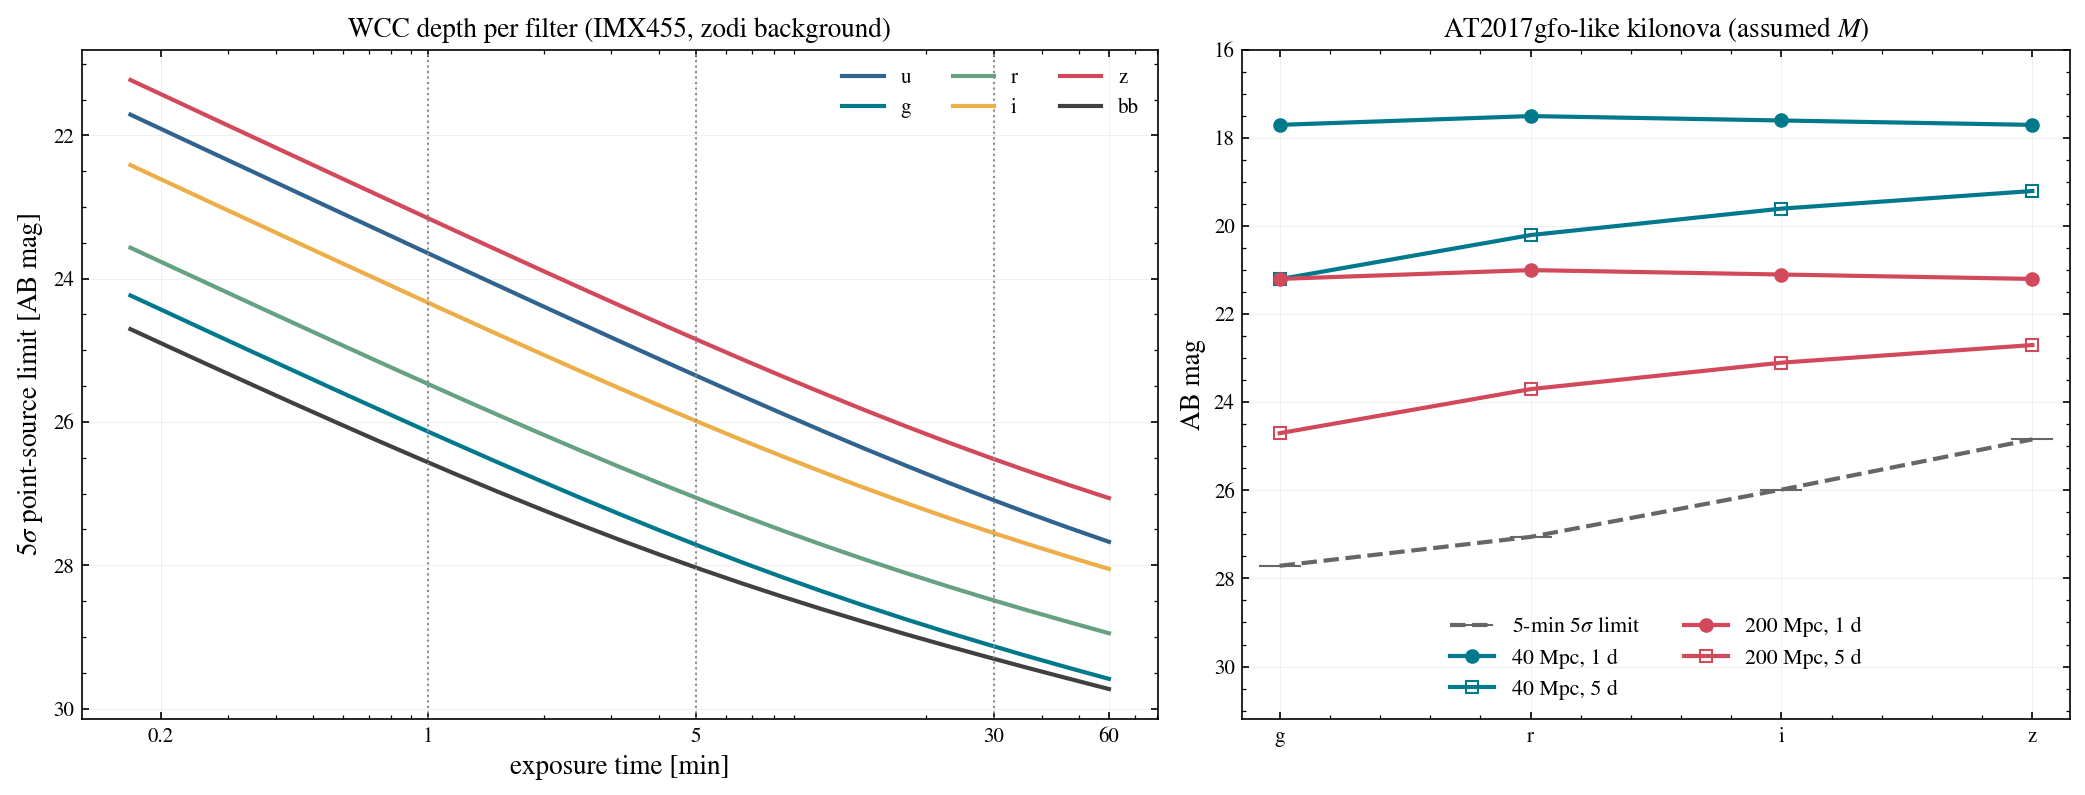

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
for f in FILTERS:
    ax1.plot(TIMES / 60, lim[f], color=COLORS[f], label=f)
for t in (1, 5, 30):
    ax1.axvline(t, color='0.55', ls=':', lw=1)
ax1.set_xscale('log')
ax1.set_xlabel('exposure time [min]')
ax1.set_ylabel(r'5$\sigma$ point-source limit [AB mag]')
ax1.set_title('WCC depth per filter (IMX455, zodi background)')
ax1.set_xticks([0.2, 1, 5, 30, 60], ['0.2', '1', '5', '30', '60'])
ax1.legend(ncol=3, loc='upper right')

x = np.arange(4)
bands = ['g', 'r', 'i', 'z']
ax2.plot(x, [table[f][1] for f in bands], color='0.4', ls='--', marker='_', ms=20, label=r'5-min 5$\sigma$ limit')
mk = {'1 d': 'o', '5 d': 's'}
dc = {40: '#00798c', 200: '#d1495b'}
for d, mu in DIST.items():
    for ep, M in M_KN.items():
        ax2.plot(x, [M[f] + mu for f in bands], marker=mk[ep], color=dc[d],
                 mfc=dc[d] if ep == '1 d' else 'none', label=f'{d} Mpc, {ep}')
ax2.set_xticks(x, bands)
ax2.set_ylim(31.2, 16)
ax2.set_ylabel('AB mag')
ax2.set_title('AT2017gfo-like kilonova (assumed $M$)')
ax2.legend(fontsize=10.5, loc='lower center', ncol=2)
ax1.invert_yaxis()   # magnitudes: bright up, deeper limits lower
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

In single exposures the WCC (IMX455) reaches 5σ AB limits of g ≈ 26.1 / 27.7 / 29.1 and r ≈ 25.5 / 27.1 / 28.5 in 1 / 5 / 30 min, with u ≈ 23.7 / 25.4 / 27.1 and z ≈ 23.2 / 24.9 / 26.5 at the shallow ends and the broad band deepest (26.6 / 28.0 / 29.3). An AT2017gfo-like kilonova at 200 Mpc is still about 3 mag (g) and 2 mag (z) above the 5-min limit at day 5. SNR = 10 takes 35 s in g and 88 s in z, so g − z to ±0.15 mag needs about 2 min of exposure per epoch, and the colour evolution can be followed well beyond 200 Mpc.

## Caveats & next steps

- **Optimistic in-focus PSF.** wcc-etc 0.1.0 uses a diffraction-perfect Airy PSF (no wavefront error or Strehl term) with a 70 mas aperture, so in-focus depths are upper limits. The noise model has photon, dark and read terms only: no cosmic rays, no stray light, no systematic floor. The zodiacal background is fixed at V = 22.5 mag/arcsec² with no dependence on ecliptic latitude. None of it is validated against measured hardware yet.
- **Isolated point source.** There is no host galaxy and no difference-imaging penalty: subtracting a template adds about √2 in noise if the template is no deeper. The SED is flat in f_ν, and the kilonova absolute magnitudes are rough values typed in by hand.
- **Ideas to extend:** (1) give the kilonova a cooling blackbody (`get_scene("blackbody", teff=...)`, ~5000 K at day 1 falling to ~2500 K at day 5) in place of the flat SED; (2) repeat with `n_reads` > 1 to see how much depth co-adding short frames costs; (3) compare the `qcmos:*` filter set, or put the kilonova on a host galaxy (see notebook 09).